In [3]:
import os
os.chdir("C:/Users/m444sa/Desktop/speech-emotion-classifier")
print(os.getcwd())

C:\Users\m444sa\Desktop\speech-emotion-classifier


In [4]:
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd


df = pd.read_csv("data/labels.csv")

# listen to one sample
sample = df[df["emotion"] == "happy"].iloc[0]
y, sr = librosa.load(sample["filepath"], sr=None)
ipd.Audio(y, rate=sr)

c:\Users\m444sa\Desktop\speech-emotion-classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


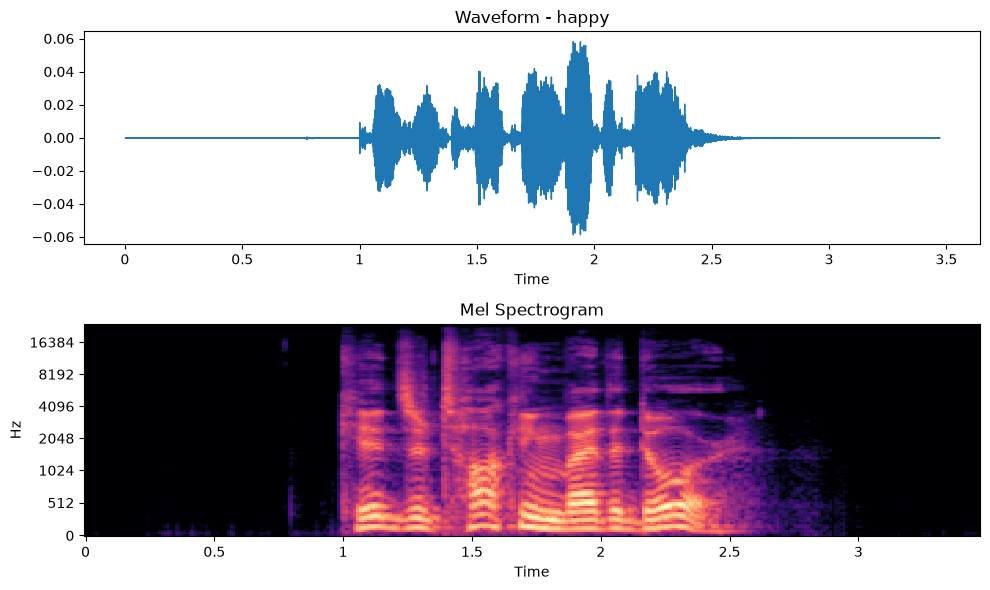

sample rate:  48000


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title(f"Waveform - {sample['emotion']}")

S = librosa.feature.melspectrogram(y=y, sr=sr)
S_db = librosa.power_to_db(S, ref=1.0)
librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="mel", ax=ax[1])
ax[1].set_title("Mel Spectrogram")

plt.tight_layout()
plt.show()
print("sample rate: ",sr)

Wav2Vec2 expects 16khz sample rate

In [6]:
from src.preprocess import load_and_process, TARGET_SR

y_processed = load_and_process(sample["filepath"])
print(y_processed.shape)  # should be (48000,) i.e. 16000 * 3.0
print(len(y_processed) / TARGET_SR, "seconds")
durations = df["filepath"].apply(lambda f: librosa.get_duration(path=f))
print(durations.describe())

(64000,)
4.0 seconds
count    1440.000000
mean        3.700665
std         0.336676
min         2.936271
25%         3.470146
50%         3.670333
75%         3.870542
max         5.271937
Name: filepath, dtype: float64


In [7]:
from src.preprocess import load_and_process, TARGET_SR, TARGET_DURATION

y_processed = load_and_process(sample["filepath"])
print(y_processed.shape)  # should now be (64000,)

(64000,)


In [8]:
import re

df["actor"] = df["filepath"].apply(lambda f: int(re.search(r"Actor_(\d+)", f).group(1)))

test_actors = [21, 22, 23, 24]

train_df = df[~df["actor"].isin(test_actors)].reset_index(drop=True)
test_df = df[df["actor"].isin(test_actors)].reset_index(drop=True)

## Feature Extraction: MFCCs

Raw audio is a long sequence of amplitude values (64,000 numbers for a 4s clip at 16kHz), whis is too much raw detail for a simple classifier to learn from directly. **MFCCs (Mel-Frequency Cepstral Coefficients)** compress this into a small set of numbers that capture the shape of the frequency spectrum, from which we can exttract speech's phonetic and emotional content.

**STEPS**
1. **Framing**: split the clip into short ( about 25ms) overlapping windows, since speech's frequency content changes too fast to analyze the whole clip at once.
2. **FFT per frame**: get the frequency spectrum of each windowed frame.
3. **Mel filterbank**: pass the spectrum through filters spaced on the *mel scale*, which mimics how human hearing is more sensitive to differences at low frequencies than high ones.
4. **Log**: take the log of the filterbank energies, mirroring how perceived loudness is roughly logarithmic.
5. **DCT (Discrete Cosine Transform)**: compress the log filterbank energies into a small number of decorrelated coefficients. We keep the first 13 (`n_mfcc=13`) — these capture the broad spectral shape (formants, spectral tilt) that matters most.

**Result:** each ~25ms frame → 13 numbers. A 4s clip (~150-180 frames) becomes a `(13, ~180)` matrix. We average across time (`np.mean(mfccs.T, axis=0)`) to collapse this into a single 13-number vector per clip enough for a quick baseline model.

In [9]:
import librosa
import numpy as np

def extract_mfcc(filepath, n_mfcc=13, sr=16000):
    y, _ = librosa.load(filepath, sr=sr)
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    return np.mean(mfccs.T, axis=0)  # average over time -> fixed-length vector

In [10]:
X_train = np.array([extract_mfcc(f) for f in train_df["filepath"]])
y_train = train_df["emotion"].values

X_test = np.array([extract_mfcc(f) for f in test_df["filepath"]])
y_test = test_df["emotion"].values

print(X_train.shape, X_test.shape)

(1200, 13) (240, 13)


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

clf = RandomForestClassifier(n_estimators=200, random_state=42)
clf.fit(X_train, y_train)

preds = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Accuracy: 0.325
              precision    recall  f1-score   support

       angry       0.40      0.78      0.53        32
        calm       0.60      0.38      0.46        32
     disgust       0.19      0.28      0.23        32
     fearful       0.45      0.31      0.37        32
       happy       0.26      0.25      0.25        32
     neutral       0.33      0.06      0.11        16
         sad       0.33      0.16      0.21        32
   surprised       0.21      0.25      0.23        32

    accuracy                           0.33       240
   macro avg       0.35      0.31      0.30       240
weighted avg       0.35      0.33      0.31       240



Wav2vec is a self-supervised framework developed by Meta AI for speech recognition and audio representation. It learns powerful speech units directly from raw, unlabeled audio data by masking parts of the input and solving a predictive or contrastive task, drastically reducing the need for large amounts of transcribed training data.

In [12]:
from transformers import Wav2Vec2FeatureExtractor

MODEL_NAME = "facebook/wav2vec2-base"
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)

In [13]:
from src.dataset import RAVDESSDataset

dataset = RAVDESSDataset(df)
audio_sample, label_sample = dataset[0]  # from your RAVDESSDataset, still 16kHz

inputs = feature_extractor(
    audio_sample.numpy(),
    sampling_rate=16000,
    return_tensors="pt"
)
print(inputs["input_values"].shape)

(1440, 3)
emotion
calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64
torch.Size([1, 64000])


In [14]:
from src.dataset import RAVDESSDataset, RAVDESSWav2Vec2Dataset, label_to_idx

train_dataset = RAVDESSWav2Vec2Dataset(train_df, feature_extractor)
test_dataset = RAVDESSWav2Vec2Dataset(test_df, feature_extractor)

sample = train_dataset[0]
print(sample["input_values"].shape)
print(sample["labels"])

torch.Size([64000])
tensor(0)


In [15]:
from transformers import Wav2Vec2ForSequenceClassification

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=8,
    label2id=label_to_idx,
    id2label={i: label for label, i in label_to_idx.items()}
)

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 4460.70it/s]
[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
quantizer.weight_proj.bias   | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
projector.weight             | MISSING    | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [16]:
import numpy as np
from sklearn.metrics import accuracy_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds)}

In [17]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="models/wav2vec2-emotion",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=10,
    learning_rate=3e-5,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)


In [18]:
trainer.train()

c:\Users\m444sa\Desktop\speech-emotion-classifier\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 